# Extended Heart use case: KAAM consistency and EBM interactions

This notebook compares one symbolic KAAM feature contribution with the corresponding EBM main effects, with and without interactions. Ten KAAMs use the same 1,000 development rows and fixed test set, but have different initializations and stratified fit/validation splits. Their formulas follow the use case: `auto_symbolic`, extract output formulas, round each to two decimals, then subtract the binary logits.

A pointwise bootstrap interval describes the mean of these ten centered curves, conditional on this fixed development set. It is not a simultaneous band, a prediction interval for individual curves, or an estimate of variability from selecting different patients. The model closest to the mean by grid RMSE is descriptive, not a new average formula.

In [6]:
from pathlib import Path
import hashlib
import json
import os
import pickle
import sys
import tempfile
import traceback

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sympy as sp
import torch
from IPython.display import display
from interpret.glassbox import ExplainableBoostingClassifier
from joblib import Parallel, delayed, parallel_config
from kan import ex_round
from sklearn.model_selection import train_test_split

# User configuration
DATASET = 'heart'
TRAIN_SIZE = 1000
FEATURE = 'Age'
SEEDS = list(range(10))
N_JOBS = 10
GRID_POINTS = 150
CURVE_BOOTSTRAP = 1000
TEST_BOOTSTRAP = 1000
BOOTSTRAP_SEED = 0
OVERWRITE_KAAM = False

cwd = Path.cwd().resolve()
ROOT = next((p for p in (cwd, *cwd.parents) if (p / 'src' / 'data.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Open this notebook within the project directory.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.data import load_data, make_sample_splits, preprocess_split
from src.models import models as model_module
from src.models.model_utils import get_metrics, load_configured_params
from src.utils import get_config

CACHE_DIR = ROOT / 'results_interpretability' / 'heart_extended'
args = get_config('performance')
args['sample_sizes'] = None
if len(set(SEEDS)) != len(SEEDS) or not SEEDS:
    raise ValueError('SEEDS must contain at least one distinct seed')
if N_JOBS < 1 or GRID_POINTS < 2 or CURVE_BOOTSTRAP < 1 or TEST_BOOTSTRAP < 1:
    raise ValueError('Jobs and bootstrap counts must be positive; GRID_POINTS must be at least 2')

## Fixed development and test rows

The indices are reconstructed with the main performance split and compared with its saved KAAM result when available. Each KAAM seed splits only the fixed development rows into stratified fit and validation subsets (80/20). Imputation and scaling are fitted on fit rows for each KAAM. The paired EBM models use the complete development set for preprocessing and training.

The horizontal axis uses the units in the project Heart CSV. The project notes that this dataset was already scaled before it was stored, so these units should not automatically be interpreted as original clinical units.

In [7]:
x, y = load_data(DATASET, args, raw=True)
test_idx, splits = make_sample_splits(DATASET, x, y, args)
dev_idx = splits[TRAIN_SIZE]
x_dev = x.iloc[dev_idx].copy()
y_dev = y.iloc[dev_idx].to_numpy()
x_test = x.iloc[test_idx].copy()
y_test = y.iloc[test_idx].to_numpy()
if FEATURE not in x_dev.columns:
    raise ValueError(f'Unknown feature {FEATURE!r}; available: {list(x_dev.columns)}')
if len(np.unique(y_dev)) != 2 or len(np.unique(y_test)) != 2:
    raise ValueError('This Heart use case requires binary labels in development and test.')
reference_path = Path(args['results_folder']) / str(TRAIN_SIZE) / DATASET / 'kan_gam.pkl'
if reference_path.is_file():
    with reference_path.open('rb') as file:
        reference = pickle.load(file)
    for key, expected in [('train_indices', dev_idx), ('test_indices', test_idx), ('y_test', y_test)]:
        if not np.array_equal(np.asarray(reference[key]).reshape(-1), np.asarray(expected).reshape(-1)):
            raise ValueError(f'Main result has different {key}: {reference_path}')
    print('Fixed split matches the saved main KAAM result.')
else:
    print('Main KAAM result is unavailable; the reconstructed split could not be cross-checked.')

kaam_params = load_configured_params(DATASET, 'kan_gam', TRAIN_SIZE, args)
ebm_params = load_configured_params(DATASET, 'ebm', TRAIN_SIZE, args)
if kaam_params['hidden_dim'] != 0 or kaam_params['mult_kan']:
    raise ValueError('The symbolic feature extraction below requires an additive KAAM.')
feature_values = pd.to_numeric(x_dev[FEATURE], errors='raise').dropna().to_numpy(dtype=float)
if len(feature_values) == 0:
    raise ValueError('The selected feature has no observed development values.')
feature_min, feature_max = float(np.min(feature_values)), float(np.max(feature_values))
if feature_min == feature_max:
    raise ValueError('The selected feature is constant in the development set.')
grid = np.linspace(feature_min, feature_max, GRID_POINTS)
print(f'Development: {len(dev_idx)} rows; fixed test: {len(test_idx)} rows; {FEATURE}: [{feature_min:.4g}, {feature_max:.4g}]')

Fixed split matches the saved main KAAM result.
Development: 1000 rows; fixed test: 2500 rows; Age: [-2.302, 1.627]


## EBM with and without interactions

Both models use the same training rows, random seed and saved Heart hyperparameters; the only changed parameter is `interactions` (saved configuration versus zero). Interactions may be selected differently by the learner; there is no new hyperparameter search. Metrics use the same held-out observations, and paired bootstrap differences are `without − with interactions`.

The unidimensional EBM curve is the **main effect** only. With interactions enabled, it does not include contributions from interaction terms involving this feature.

In [8]:
x_ebm_dev, x_ebm_test, ebm_preprocessing = preprocess_split(x_dev, x_test)
ebm_models, ebm_predictions = {}, {}
for key, interactions in [('with', ebm_params['interactions']), ('without', 0)]:
    params = dict(ebm_params)
    params['interactions'] = interactions
    ebm = ExplainableBoostingClassifier(**params)
    ebm.fit(x_ebm_dev, y_dev)
    proba = np.asarray(ebm.predict_proba(x_ebm_test))
    pred = np.asarray(ebm.predict(x_ebm_test))
    ebm_models[key] = ebm
    ebm_predictions[key] = (pred, proba)
    print(f'EBM {key} interactions fitted; interaction setting={interactions}', flush=True)
if not np.array_equal(ebm_models['with'].classes_, ebm_models['without'].classes_):
    raise ValueError('EBM class orders differ.')
classes = np.asarray(ebm_models['with'].classes_)

rng = np.random.default_rng(BOOTSTRAP_SEED)
eb_samples = {'with': {}, 'without': {}}
for _ in range(TEST_BOOTSTRAP):
    sampled = rng.choice(len(y_test), len(y_test), replace=True)
    if not np.array_equal(np.unique(y_test[sampled]), classes):
        continue
    for name in eb_samples:
        pred, proba = ebm_predictions[name]
        metrics = get_metrics(y_test[sampled], pred[sampled], proba[sampled], classes=classes, n_bins=args['ece_bins'])
        for metric, value in metrics.items():
            eb_samples[name].setdefault(metric, []).append(value)
valid_test_bootstrap = len(eb_samples['with'].get('accuracy', []))
if not valid_test_bootstrap:
    raise ValueError('No paired test bootstrap sample contains all classes.')

def summary(values):
    values = np.asarray(values, dtype=float)
    lo, hi = np.percentile(values, [2.5, 97.5])
    return f'{values.mean():.3f} ({lo:.3f}–{hi:.3f})'

main_keys = {'Accuracy': 'accuracy', 'ROC-AUC': 'roc_auc', 'F1': 'f1', 'Precision': 'precision', 'Recall': 'recall'}
calibration_keys = {'ECE': 'ece', 'Brier score': 'brier', 'Log loss': 'log_loss'}
def ebm_table(keys):
    rows = []
    for label, name in [('With interactions', 'with'), ('Without interactions', 'without')]:
        rows.append({'Model': label, **{heading: summary(eb_samples[name][key]) for heading, key in keys.items()}})
    rows.append({'Model': 'Difference: without − with',
                 **{heading: summary(np.asarray(eb_samples['without'][key]) - np.asarray(eb_samples['with'][key]))
                    for heading, key in keys.items()}})
    return pd.DataFrame(rows)
print(f'Valid paired test bootstrap samples: {valid_test_bootstrap}/{TEST_BOOTSTRAP}')

EBM with interactions fitted; interaction setting=5
EBM without interactions fitted; interaction setting=0
Valid paired test bootstrap samples: 1000/1000


##### EBM predictive metrics and paired differences

Cells show bootstrap means and percentile 95% intervals. Positive differences favor the model without interactions for classification metrics; negative differences favor it for ECE, Brier and log loss. These intervals do not include retraining variability.

In [9]:
display(ebm_table(main_keys))
display(ebm_table(calibration_keys))

,Model,Accuracy,ROC-AUC,F1,Precision,Recall
0,With interactions,0.908 (0.896–0.918),0.831 (0.809–0.854),0.094 (0.047–0.146),0.603 (0.385–0.833),0.051 (0.025–0.082)
1,Without interactions,0.908 (0.897–0.919),0.829 (0.807–0.852),0.057 (0.018–0.099),0.869 (0.600–1.000),0.029 (0.009–0.052)
2,Difference: without − with,0.001 (-0.002–0.004),-0.002 (-0.009–0.005),-0.037 (-0.075–-0.007),0.266 (0.024–0.530),-0.022 (-0.043–-0.004)


,Model,ECE,Brier score,Log loss
0,With interactions,0.012 (0.005–0.021),0.073 (0.066–0.080),0.247 (0.226–0.268)
1,Without interactions,0.018 (0.009–0.028),0.073 (0.066–0.081),0.251 (0.231–0.272)
2,Difference: without − with,0.006 (-0.006–0.015),0.000 (-0.001–0.001),0.004 (0.001–0.007)


## Ten parallel KAAM fits and symbolic formulas

Each job uses its own process and temporary working directory to isolate pykan files. A notebook-local constructor wrapper passes the run's seed to KAN; this corrects the existing fixed constructor seed for this experiment without changing project code. Fit/validation splits are stratified. The symbolic selection uses fit rows, not test.

Each successful seed is cached separately under `results_interpretability/heart_extended/`. Compatible results are reused on rerun; `OVERWRITE_KAAM=True` repeats them. Cache signatures include the selected data, indices, parameters and split seed. Failures are shown and do not silently replace a formula.

In [10]:
def data_signature(x_dev, y_dev, x_test, y_test, dev_idx, test_idx, params, split_seed):
    digest = hashlib.sha256()
    for frame in (x_dev, x_test):
        digest.update(pd.util.hash_pandas_object(frame, index=True).values.tobytes())
        digest.update(repr(list(frame.columns)).encode())
    for array in (y_dev, y_test, dev_idx, test_idx):
        digest.update(np.asarray(array).tobytes())
    digest.update(json.dumps({'params': params, 'split_seed': split_seed, 'version': 1}, sort_keys=True).encode())
    return digest.hexdigest()

signature = data_signature(x_dev, y_dev, x_test, y_test, dev_idx, test_idx, kaam_params, args['split_seed'])
CACHE_DIR.mkdir(parents=True, exist_ok=True)


def fit_symbolic_seed(seed, x_dev, y_dev, x_test, y_test, dev_idx, test_idx, params, signature, cache_dir, overwrite):
    cache_dir = Path(cache_dir)
    path = cache_dir / f'kaam_seed_{seed}.pkl'
    try:
        if path.exists() and not overwrite:
            with path.open('rb') as file:
                cached = pickle.load(file)
            if cached.get('signature') != signature or cached.get('seed') != seed:
                raise ValueError(f'Cache is incompatible: {path}; inspect it or enable OVERWRITE_KAAM')
            return seed, 'reused', cached, ''
        torch.set_num_threads(1)
        indices = np.arange(len(x_dev))
        fit_pos, val_pos = train_test_split(indices, test_size=0.2, random_state=seed, stratify=y_dev)
        x_fit, x_val, preprocessing = preprocess_split(x_dev.iloc[fit_pos], x_dev.iloc[val_pos])
        run_params = dict(params)
        run_params['seed'] = seed
        previous_dir = os.getcwd()
        original_constructor = model_module.KAN
        def seeded_constructor(*args, **kwargs):
            kwargs['seed'] = seed
            return original_constructor(*args, **kwargs)
        with tempfile.TemporaryDirectory(prefix='heart-kaam-') as work_dir:
            try:
                os.chdir(work_dir)
                model_module.KAN = seeded_constructor
                model = model_module.Kan_model()
                model.set_params(**run_params)
                model.run_model(x_fit, x_val, y_dev[fit_pos], y_dev[val_pos], verbose=0)
                # Test is evaluated but is never used for the split, fitting or symbolic selection.
                test_scaled = x_test.astype(float).copy()
                test_scaled = test_scaled.fillna(pd.Series(preprocessing['imputation_values']))
                test_scaled = (test_scaled - pd.Series(preprocessing['means'])) / pd.Series(preprocessing['stds'])
                y_proba = np.asarray(model.predict_proba(test_scaled))
                y_pred = np.asarray(model.predict(test_scaled)).reshape(-1)
                model.model(model.dataset['train_input'])
                model.model.auto_symbolic(verbose=0)
                formulas, symbols = model.model.symbolic_formula()
                if len(formulas) != 2:
                    raise ValueError('Expected two binary logits from KAAM')
                rounded = [ex_round(formula, 2) for formula in formulas]
                delta = rounded[1] - rounded[0]
                result = {'signature': signature, 'seed': seed, 'params': run_params,
                          'fit_indices': np.asarray(dev_idx)[fit_pos], 'validation_indices': np.asarray(dev_idx)[val_pos],
                          'test_indices': np.asarray(test_idx), 'preprocessing': preprocessing,
                          'features': list(x_dev.columns), 'symbols': [str(s) for s in symbols],
                          'formula': str(delta), 'output_formulas': [str(f) for f in rounded],
                          'y_test': np.asarray(y_test), 'y_pred': y_pred, 'y_proba': y_proba}
            finally:
                model_module.KAN = original_constructor
                os.chdir(previous_dir)
        fd, temporary = tempfile.mkstemp(prefix=f'.seed-{seed}-', suffix='.tmp', dir=cache_dir)
        try:
            with os.fdopen(fd, 'wb') as file:
                pickle.dump(result, file, protocol=pickle.HIGHEST_PROTOCOL)
            os.replace(temporary, path)
        finally:
            if os.path.exists(temporary):
                os.unlink(temporary)
        return seed, 'completed', result, ''
    except Exception:
        return seed, 'failed', None, traceback.format_exc()


runs, failures = {}, []
with parallel_config(backend='loky', inner_max_num_threads=1):
    finished = Parallel(n_jobs=N_JOBS, return_as='generator_unordered')(
        delayed(fit_symbolic_seed)(seed, x_dev, y_dev, x_test, y_test, dev_idx, test_idx,
                                   kaam_params, signature, CACHE_DIR, OVERWRITE_KAAM)
        for seed in SEEDS
    )
    for count, (seed, status, result, error) in enumerate(finished, 1):
        print(f'KAAM progress: {count}/{len(SEEDS)} | seed {seed}: {status}', flush=True)
        if result is not None:
            runs[seed] = result
        else:
            failures.append({'Seed': seed, 'Error': error})
if failures:
    display(pd.DataFrame(failures))
print(f'Completed or reused: {len(runs)}/{len(SEEDS)}')

KAAM progress: 1/10 | seed 0: reused
KAAM progress: 2/10 | seed 1: reused
KAAM progress: 3/10 | seed 2: reused


/home/almo/anaconda3/envs/logistickan/lib/python3.11/site-packages/sympy/core/sympify.py:475: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  return sympify(float(a))


KAAM progress: 4/10 | seed 8: completed


/home/almo/anaconda3/envs/logistickan/lib/python3.11/site-packages/sympy/core/sympify.py:475: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  return sympify(float(a))


KAAM progress: 5/10 | seed 7: completed


/home/almo/anaconda3/envs/logistickan/lib/python3.11/site-packages/sympy/core/sympify.py:475: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  return sympify(float(a))


... (5 outputs left out)

/home/almo/anaconda3/envs/logistickan/lib/python3.11/site-packages/sympy/core/sympify.py:475: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  return sympify(float(a))


KAAM progress: 9/10 | seed 5: completed


/home/almo/anaconda3/envs/logistickan/lib/python3.11/site-packages/sympy/core/sympify.py:475: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  return sympify(float(a))


KAAM progress: 10/10 | seed 9: completed
Completed or reused: 10/10


## Symbolic curve extraction and pointwise bootstrap interval

For each seed we extract the terms that depend on the selected variable from the rounded logit-difference expression. Its own fit-only preprocessing is applied before evaluating the formula. Curves are centered to have zero mean over the **same fixed development rows**, which makes offsets comparable.

Curves must be real and finite over both the grid and the development values. A formula that fails is reported; it is not replaced. The bootstrap resamples complete model curves. If fewer than all selected models yield valid curves, the incomplete set is shown but the interval and representative formula are withheld.

In [11]:
def feature_curve(run, feature, grid, reference_values):
    symbols = [sp.Symbol(s) for s in run['symbols']]
    feature_index = run['features'].index(feature)
    symbol = symbols[feature_index]
    expr = sp.sympify(run['formula'], locals={str(s): s for s in symbols})
    terms = sp.Add.make_args(sp.expand(expr))
    cross_terms = [term for term in terms if len(term.free_symbols) > 1]
    if cross_terms:
        raise ValueError('Formula has cross-feature terms; cannot extract an additive contribution')
    feature_expr = sp.Add(*(term for term in terms if symbol in term.free_symbols))
    function = sp.lambdify(symbol, feature_expr, modules='numpy')
    means, stds = run['preprocessing']['means'], run['preprocessing']['stds']
    imputed = np.asarray(reference_values, dtype=float)
    imputed = np.where(np.isnan(imputed), run['preprocessing']['imputation_values'][feature], imputed)
    def evaluate(values):
        transformed = (np.asarray(values, dtype=float) - means[feature]) / stds[feature]
        with np.errstate(all='ignore'):
            output = np.asarray(function(transformed))
        if np.iscomplexobj(output):
            raise ValueError('Complex feature contribution')
        output = np.asarray(output, dtype=float)
        output = np.broadcast_to(output, transformed.shape)
        if not np.isfinite(output).all():
            raise ValueError('Non-finite feature contribution on grid or development rows')
        return output
    center = float(evaluate(imputed).mean())
    return evaluate(grid) - center, str(feature_expr), center

curves, curve_info, curve_failures = {}, {}, []
for seed in SEEDS:
    if seed not in runs:
        continue
    try:
        curve, expr, center = feature_curve(runs[seed], FEATURE, grid, x_dev[FEATURE].to_numpy(dtype=float))
        curves[seed] = curve
        curve_info[seed] = {'feature_expression': expr, 'centering_offset': center}
    except Exception as exc:
        curve_failures.append({'Seed': seed, 'Issue': str(exc)})
if curve_failures:
    display(pd.DataFrame(curve_failures))
print(f'Valid curves: {len(curves)}/{len(SEEDS)}')

curve_complete = len(curves) == len(SEEDS) and len(SEEDS) >= 2
if curve_complete:
    matrix = np.stack([curves[seed] for seed in SEEDS])
    mean_curve = matrix.mean(axis=0)
    rng = np.random.default_rng(BOOTSTRAP_SEED)
    draw = rng.integers(0, len(SEEDS), size=(CURVE_BOOTSTRAP, len(SEEDS)))
    boot_means = matrix[draw].mean(axis=1)
    lower_curve, upper_curve = np.percentile(boot_means, [2.5, 97.5], axis=0)
    rmse = np.sqrt(np.mean((matrix - mean_curve) ** 2, axis=1))
    representative_seed = SEEDS[int(np.argmin(rmse))]
    display(pd.DataFrame({'Seed': SEEDS, 'RMSE to mean': rmse}).sort_values('RMSE to mean'))
    print(f'Representative seed: {representative_seed}')
    print('Feature expression in transformed inputs:', curve_info[representative_seed]['feature_expression'])
    print('Full rounded logit-difference formula:', runs[representative_seed]['formula'])
else:
    print('All selected curves are required before the interval and representative are calculated.')

Valid curves: 10/10


,Seed,RMSE to mean
4,4,0.086857
7,7,0.112380
2,2,0.115166
9,9,0.115239
1,1,0.145543
6,6,0.166473
8,8,0.169504
0,0,0.191398
3,3,0.219725
5,5,0.291534


Representative seed: 4
Feature expression in transformed inputs: -0.61*sin(0.5*x_19 + 8.73)
Full rounded logit-difference formula: 0.32*x_1 + 0.1*x_10 + 0.1*x_12 - 0.1*x_13 + 0.1*x_17 + 0.35*x_18 + 0.37*x_2 + 0.04*x_3 + 0.1*x_5 + 0.06*x_6 - 0.04*x_8 - 0.29*sin(5.79*x_14 - 2.41) - 0.1*sin(0.98*x_16 + 2.42) - 0.61*sin(0.5*x_19 + 8.73) - 0.03*sin(0.82*x_20 - 5.01) + 0.39*sin(0.3*x_4 - 1.03) + 0.53*cos(0.61*x_14 - 8.6) - 0.52*cos(0.28*x_4 + 0.73) + 1.2 - 0.28/(1.68 - 2.62*x_20)**2


##### KAAM consistency across training runs

Thin lines are the centered individual curves. The black dashed line is their mean, the shaded region is the pointwise 95% percentile bootstrap interval for that mean, and the highlighted line is the trained formula with the smallest grid RMSE to the mean. These curves include variability from both initialization and fit/validation split.

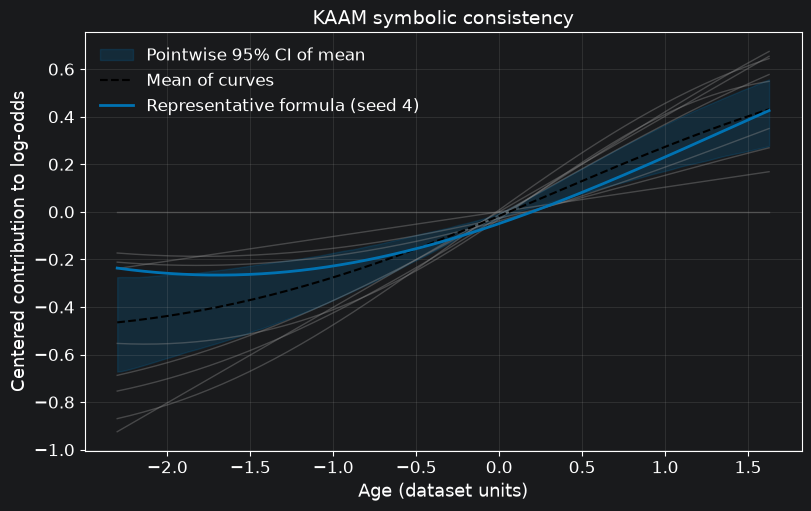

In [12]:
if curve_complete:
    plt.rcParams.update({'font.size': 12, 'axes.titlesize': 14, 'axes.labelsize': 13})
    fig_consistency, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
    for seed, curve in curves.items():
        ax.plot(grid, curve, color='#8c8c8c', alpha=0.4, linewidth=1)
    ax.fill_between(grid, lower_curve, upper_curve, color='#0072B2', alpha=0.2, label='Pointwise 95% CI of mean')
    ax.plot(grid, mean_curve, color='black', linestyle='--', label='Mean of curves')
    ax.plot(grid, curves[representative_seed], color='#0072B2', linewidth=2, label=f'Representative formula (seed {representative_seed})')
    ax.set(xlabel=f'{FEATURE} (dataset units)', ylabel='Centered contribution to log-odds', title='KAAM symbolic consistency')
    ax.grid(alpha=0.2)
    ax.legend(frameon=False)
    plt.show()

## Comparison with EBM main effects

Each curve is centered by its average over the same development observations. KAAM uses the representative formula. EBM main effects are evaluated using the trained model's bins and drawn as steps; the panel with interactions omits the separate interaction-term contributions. Identical vertical limits aid visual comparison. The EBM models use a single fit each, so the KAAM bootstrap band is not an EBM uncertainty interval.

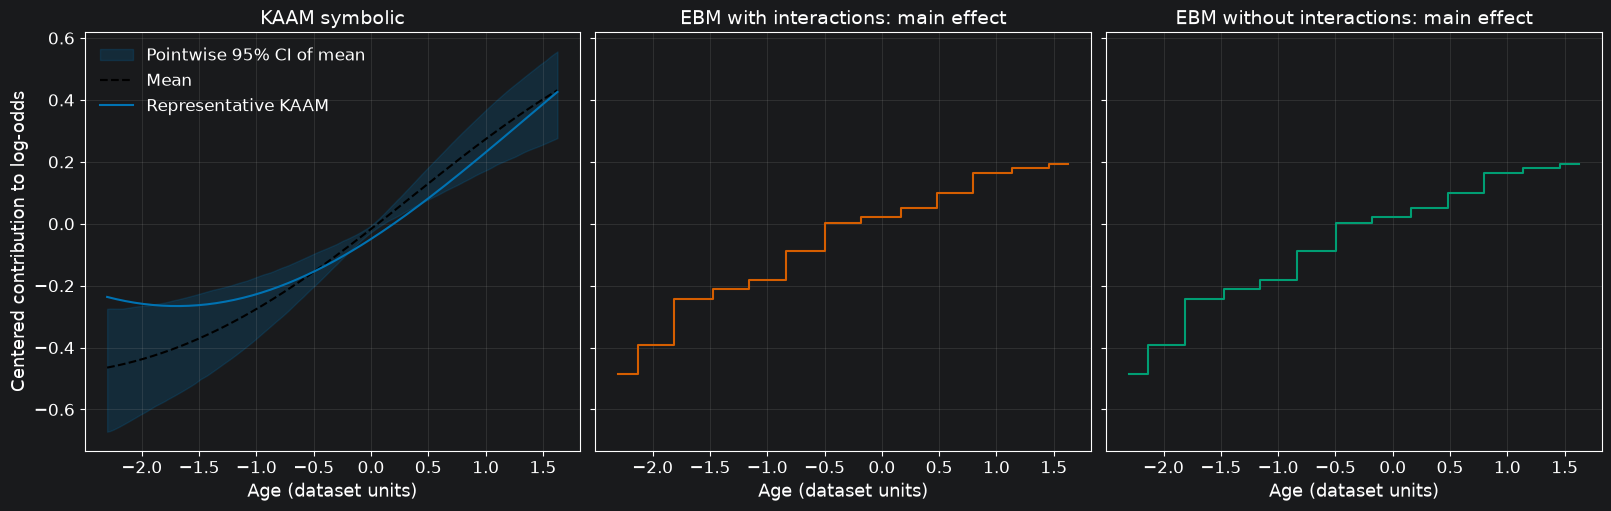

In [13]:
def ebm_feature_curve(model, x_reference, feature, grid, preprocessing):
    feature_index = list(x_reference.columns).index(feature)
    matching = [i for i, term in enumerate(model.term_features_) if tuple(term) == (feature_index,)]
    if len(matching) != 1:
        raise ValueError(f'Expected exactly one EBM main effect for {feature}')
    term = matching[0]
    mean = preprocessing['means'][feature]
    std = preprocessing['stds'][feature]
    # Other features are held at fixed transformed values; a main effect depends only on this feature.
    grid_data = pd.DataFrame(np.zeros((len(grid), x_reference.shape[1])), columns=x_reference.columns)
    grid_data[feature] = (grid - mean) / std
    grid_effect = np.asarray(model.eval_terms(grid_data))[:, term]
    reference_effect = np.asarray(model.eval_terms(x_ebm_dev))[:, term]
    if not np.isfinite(grid_effect).all() or not np.isfinite(reference_effect).all():
        raise ValueError('EBM main effect is not finite')
    return grid_effect - reference_effect.mean()

if curve_complete:
    ebm_with_curve = ebm_feature_curve(ebm_models['with'], x_dev, FEATURE, grid, ebm_preprocessing)
    ebm_without_curve = ebm_feature_curve(ebm_models['without'], x_dev, FEATURE, grid, ebm_preprocessing)
    fig_comparison, axes = plt.subplots(1, 3, figsize=(16, 5), sharex=True, sharey=True, constrained_layout=True)
    axes[0].fill_between(grid, lower_curve, upper_curve, color='#0072B2', alpha=0.2, label='Pointwise 95% CI of mean')
    axes[0].plot(grid, mean_curve, color='black', linestyle='--', label='Mean')
    axes[0].plot(grid, curves[representative_seed], color='#0072B2', label='Representative KAAM')
    axes[0].set_title('KAAM symbolic')
    axes[0].legend(frameon=False)
    axes[1].step(grid, ebm_with_curve, where='mid', color='#D55E00')
    axes[1].set_title('EBM with interactions: main effect')
    axes[2].step(grid, ebm_without_curve, where='mid', color='#009E73')
    axes[2].set_title('EBM without interactions: main effect')
    for ax in axes:
        ax.set_xlabel(f'{FEATURE} (dataset units)')
        ax.grid(alpha=0.2)
    axes[0].set_ylabel('Centered contribution to log-odds')
    plt.show()

## Export

The cached formulas use the transformed input variables listed in each run's `symbols` and `features`; the plotted X axis is converted back to the units of the stored Heart dataset. Uncomment a line to save a figure. Outputs are not exported automatically.

In [14]:
# fig_consistency.savefig('heart_kaam_consistency.pdf', bbox_inches='tight')
# fig_comparison.savefig('heart_kaam_ebm_comparison.pdf', bbox_inches='tight')

## Additional feature comparisons with EBM bagging bands

The following cells reuse the KAAM formulas and fitted EBM models already held in memory. They do not fit or symbolify any model. Run the earlier data, EBM and KAAM cells first. Each feature is evaluated on its own grid, using observed values for features with at most 15 distinct values and a continuous grid otherwise.

The KAAM band is a **pointwise 95% percentile bootstrap interval for the mean of independently trained model curves**. The EBM bands are the package's **main-effect score ± one standard deviation across outer bags**. They are not 95% confidence intervals and do not describe the same source of variability. Heart's saved EBM configuration uses four outer bags. The EBM-with-interactions panel displays the main effect only; interaction contributions are not included.

In [15]:
def ebm_main_effect_with_band(model, feature, values):
    feature_index = list(x_dev.columns).index(feature)
    matches = [i for i, term in enumerate(model.term_features_) if tuple(term) == (feature_index,)]
    if len(matches) != 1:
        raise ValueError(f'Expected exactly one EBM main effect for {feature}')
    term = matches[0]
    explanation = model.explain_global().data(term)
    scores = np.asarray(explanation['scores'], dtype=float)
    lower = explanation['lower_bounds']
    upper = explanation['upper_bounds']
    if lower is None or upper is None:
        raise ValueError('EBM does not provide outer-bag standard-deviation bounds')
    lower, upper = np.asarray(lower, dtype=float), np.asarray(upper, dtype=float)
    edges = np.asarray(explanation['names'], dtype=float)
    if len(edges) != len(scores) + 1 or lower.shape != scores.shape or upper.shape != scores.shape:
        raise ValueError(f'Unexpected EBM bin or bounds format for {feature}')
    transformed = (np.asarray(values, dtype=float) - ebm_preprocessing['means'][feature]) / ebm_preprocessing['stds'][feature]
    bin_index = np.searchsorted(edges[1:-1], transformed, side='right')
    grid_data = pd.DataFrame(np.zeros((len(values), x_dev.shape[1])), columns=x_dev.columns)
    grid_data[feature] = transformed
    observed = np.asarray(model.eval_terms(grid_data))[:, term]
    if not np.allclose(scores[bin_index], observed, rtol=1e-8, atol=1e-8):
        raise ValueError(f'Explanation bins do not reproduce EBM main-effect predictions for {feature}')
    center = float(np.asarray(model.eval_terms(x_ebm_dev))[:, term].mean())
    return scores[bin_index] - center, lower[bin_index] - center, upper[bin_index] - center


def plot_feature_comparison(feature):
    if len(runs) != len(SEEDS):
        print(f'{feature}: all selected KAAM runs are required; inspect failures above.')
        return
    if feature not in x_dev.columns:
        raise ValueError(f'Unknown feature {feature!r}')
    observed = pd.to_numeric(x_dev[feature], errors='raise').dropna().to_numpy(dtype=float)
    if not len(observed):
        raise ValueError(f'No observed development values for {feature}')
    unique = np.unique(observed)
    if len(unique) < 2:
        raise ValueError(f'{feature} is constant in development data')
    discrete = len(unique) <= 15
    values = unique if discrete else np.linspace(unique[0], unique[-1], GRID_POINTS)
    curves_by_seed, errors = {}, []
    for seed in SEEDS:
        try:
            curve, _, _ = feature_curve(runs[seed], feature, values, x_dev[feature].to_numpy(dtype=float))
            curves_by_seed[seed] = curve
        except Exception as exc:
            errors.append({'Seed': seed, 'Issue': str(exc)})
    if errors:
        print(f'{feature}: cannot display a complete KAAM bootstrap comparison.')
        display(pd.DataFrame(errors))
        return
    matrix = np.stack([curves_by_seed[seed] for seed in SEEDS])
    mean = matrix.mean(axis=0)
    rng = np.random.default_rng(BOOTSTRAP_SEED)
    samples = rng.integers(0, len(SEEDS), size=(CURVE_BOOTSTRAP, len(SEEDS)))
    low, high = np.percentile(matrix[samples].mean(axis=1), [2.5, 97.5], axis=0)
    distances = np.sqrt(np.mean((matrix - mean) ** 2, axis=1))
    representative = SEEDS[int(np.argmin(distances))]
    with_values = ebm_main_effect_with_band(ebm_models['with'], feature, values)
    without_values = ebm_main_effect_with_band(ebm_models['without'], feature, values)

    fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharex=True, sharey=True, constrained_layout=True)
    for curve in matrix:
        axes[0].plot(values, curve, color='#888888', alpha=0.3, linewidth=0.8)
    axes[0].fill_between(values, low, high, color='#0072B2', alpha=0.2, label='95% pointwise CI of mean')
    axes[0].plot(values, mean, color='black', linestyle='--', label='Mean')
    axes[0].plot(values, curves_by_seed[representative], color='#0072B2', marker='o' if discrete else None,
                 label=f'Representative KAAM (seed {representative})')
    axes[0].set_title('KAAM symbolic')
    axes[0].legend(frameon=False, fontsize=9)
    for ax, title, result, color in [(axes[1], 'EBM with interactions: main effect', with_values, '#D55E00'),
                                     (axes[2], 'EBM without interactions: main effect', without_values, '#009E73')]:
        score, lower, upper = result
        if discrete:
            ax.fill_between(values, lower, upper, color=color, alpha=0.2, label='±1 SD across bags')
            ax.plot(values, score, marker='o', linestyle='none', color=color, label='Main effect')
        else:
            ax.fill_between(values, lower, upper, step='mid', color=color, alpha=0.2, label='±1 SD across bags')
            ax.step(values, score, where='mid', color=color, label='Main effect')
        ax.set_title(title)
        ax.legend(frameon=False, fontsize=9)
    for ax in axes:
        ax.set_xlabel(f'{feature} (dataset units)')
        ax.grid(alpha=0.2)
        if discrete:
            ax.set_xticks(values)
    axes[0].set_ylabel('Centered contribution to log-odds')
    fig.suptitle(f'{feature}: KAAM and EBM main effects')
    plt.show()
    print(f'{feature}: representative KAAM seed {representative}; mean of {len(SEEDS)} curves.')
    return fig

##### Age — KAAM and EBM contributions

Age is shown in the units stored in the Heart dataset. The three panels use the same training rows for centering and share a vertical scale.

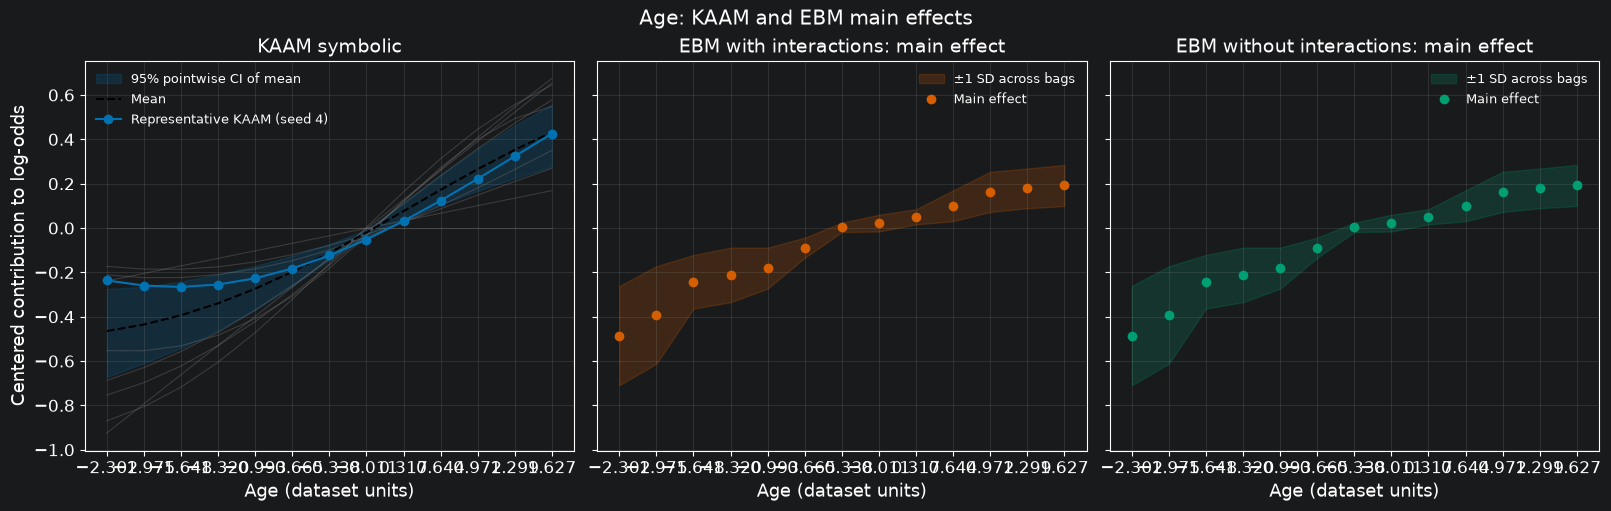

Age: representative KAAM seed 4; mean of 10 curves.


In [16]:
fig_Age = plot_feature_comparison('Age')

##### BMI — KAAM and EBM contributions

BMI is shown in the units stored in the Heart dataset. The three panels use the same training rows for centering and share a vertical scale.

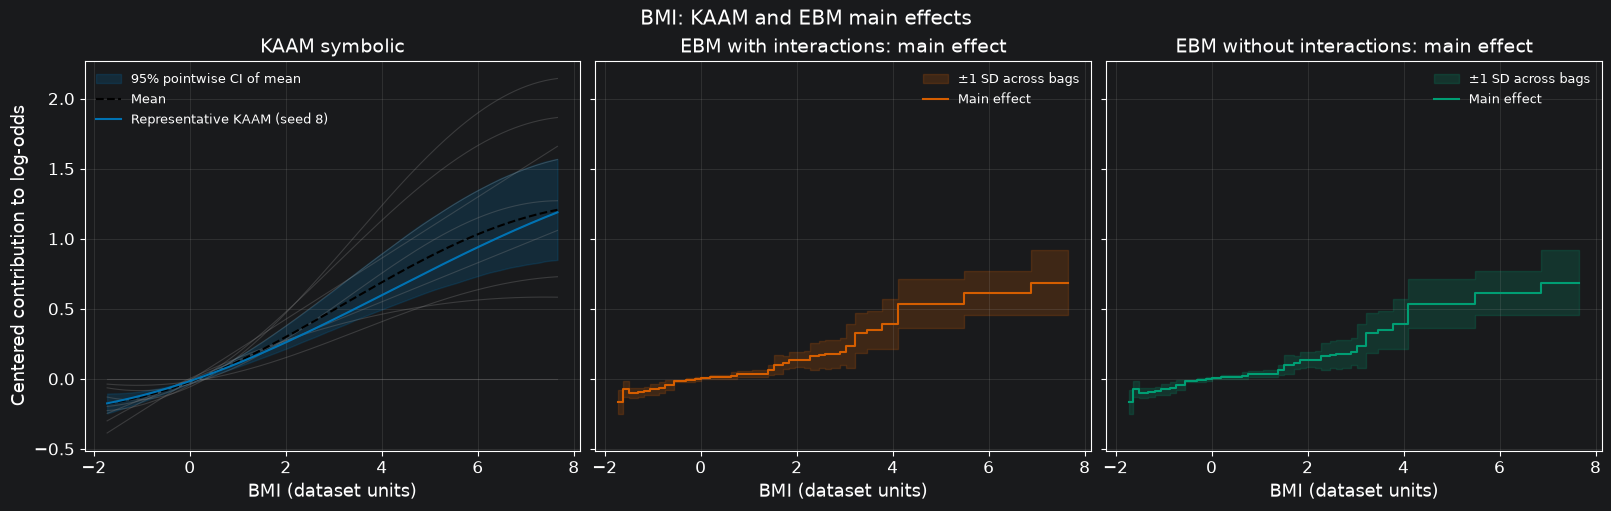

BMI: representative KAAM seed 8; mean of 10 curves.


In [17]:
fig_BMI = plot_feature_comparison('BMI')

##### GenHlth — KAAM and EBM contributions

General health is an ordinal variable; only observed encoded values are shown. The three panels use the same training rows for centering and share a vertical scale.

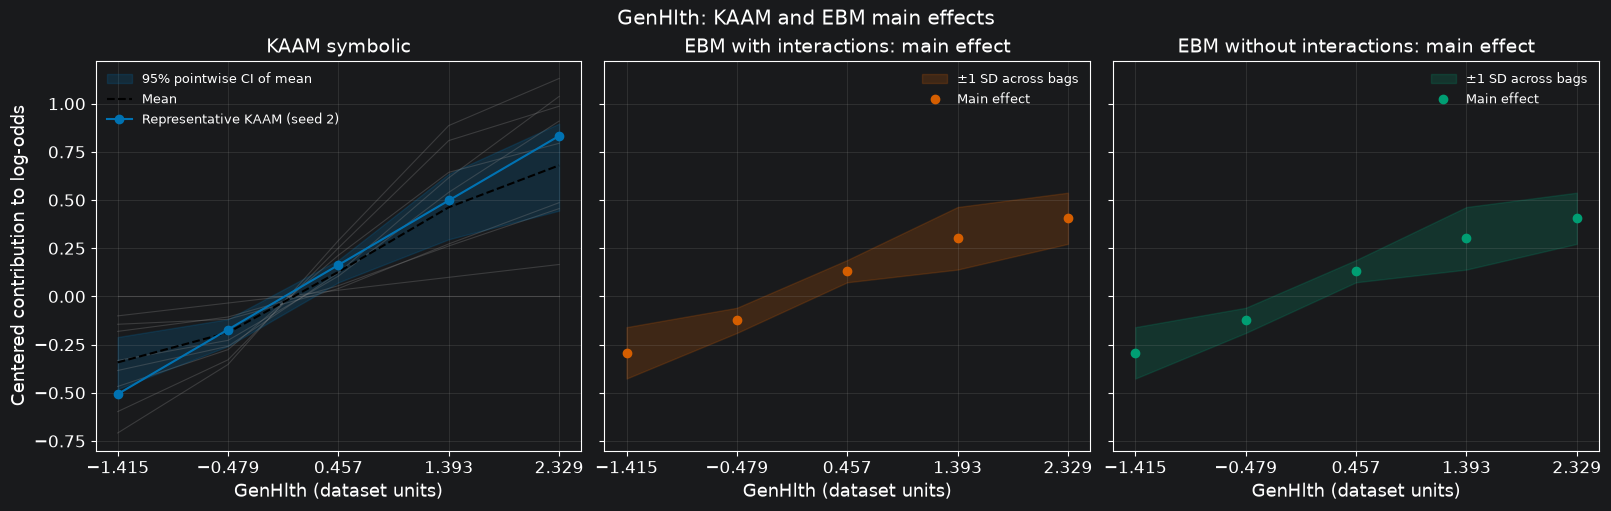

GenHlth: representative KAAM seed 2; mean of 10 curves.


In [18]:
fig_GenHlth = plot_feature_comparison('GenHlth')